# 과제: 호텔 예약 데이터를 정제하고 사전 확인 대상 찾기

## 비즈니스 배경

호텔 예약 운영팀은 예약 취소에 따른 객실 운영의 불확실성을 줄이기 위해 예약 현황을 분석합니다. 분석 담당자는 전달받은 CSV 파일의 구조와 데이터 품질을 확인하고, 결측치와 오류 값을 처리합니다. 이후 예약 경로와 예약 선행일수에 따른 취소 비율, 숙박일수, 동반 인원수 등을 분석하고, 운영팀이 정한 조건에 맞는 사전 확인 대상 예약 목록을 추출해 분석 결과를 설명합니다.

## 데이터 설명
`hotel_bookings.csv`는 교육용으로 제작한 가상의 호텔 예약 데이터이며, 결측치와 오류 값이 일부 포함되어 있습니다. 한 행은 하나의 예약을 의미합니다.

|열 이름|설명|
|---|---|
|`booking_id`|예약 식별 번호|
|`lead_time`|예약일부터 예정 입실일까지의 일수|
|`weekend_nights`|주말 숙박일수|
|`weekday_nights`|평일 숙박일수|
|`adults`|성인 인원수|
|`children`|어린이 인원수|
|`room_type`|객실 유형: Standard, Deluxue, Suite|
|`daily_rate`|예약에 적용된 1박당 객실 요금, 단위: 원|
|`booking_channel`|예약 경로: Direct, Online, Agency|
|`is_canceled`|취소 여부: 0=미취소, 1=취소|


## 데이터 및 업무 조건
* 예약 번호는 중복되지 않으며, `is_canceled`에는 결측치가 없습니다.
* `lead_time`, 숙박일수, 인원수에는 음수가 올 수 없습니다.
* 이 호텔은 무료 숙박을 취급하지 않으므로 `daily_rate`는 0보다 커야합니다.
* `children`의 결측값은 `어린이 0명`을 의미하지 않습니다.
* 객실 유형에 따라 요금이 다르므로, 높은 요금이 반드시 오류는 아닙니다.
* 미취소 예약은 기준 시점에 취소되지 않은 예약이며, 최종 투숙 완료를 의미하지 않습니다.

## 문제 1. CSV 파일 읽기, 기본 정보 확인

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# CSV 파일을 읽어 bookin_raw df에 저장
booking_raw = pd.read_csv('./hotel_bookings.csv')

In [4]:
# 처음 5개 행
booking_raw.head(5)

,booking_id,lead_time,weekend_nights,weekday_nights,adults,children,room_type,daily_rate,booking_channel,is_canceled
0,HB0204,15.0,2.0,5.0,2.0,1.0,Deluxe,180000.0,Direct,0
1,HB0267,7.0,0.0,4.0,2.0,0.0,Standard,130000.0,Direct,0
2,HB0153,28.0,2.0,4.0,1.0,0.0,Standard,70000.0,Online,0
3,HB0010,30.0,2.0,3.0,2.0,2.0,Standard,130000.0,Online,0
4,HB0234,171.0,0.0,4.0,2.0,1.0,Standard,120000.0,Agency,0


In [5]:
# 전체 행 수/열 수
print(f'total rows: {len(booking_raw)}')
print(f'ttoal columns: {len(booking_raw.columns)}')

total rows: 300
ttoal columns: 10


In [7]:
# 각 열의 자료형 확인
booking_raw.dtypes

booking_id             str
lead_time          float64
weekend_nights     float64
weekday_nights     float64
adults             float64
children           float64
room_type              str
daily_rate         float64
booking_channel        str
is_canceled          int64
dtype: object

In [26]:
# 수치형 열의 기술 통계량을 출력

def make_stat(col_name, sdt):
    stat = {
        'name': col_name,
        'dtype': sdt,
        'mean': booking_raw[col_name].mean(),
        'std': booking_raw[col_name].std(),
        'min': booking_raw[col_name].min(),
        'q25': booking_raw[col_name].quantile(0.25),
        'median': booking_raw[col_name].median(),
        'q75': booking_raw[col_name].quantile(0.75),
        'max': booking_raw[col_name].max()
    }
    
    return stat

stats = []
for col_name, dtype in pd.Series(booking_raw.dtypes).items():
    sdt = str(dtype)
    if sdt == 'float64':
        stats.append(make_stat(col_name, sdt))

stats = pd.DataFrame(stats)
stats

,name,dtype,mean,std,min,q25,median,q75,max
0,lead_time,float64,47.677852,51.739801,-1.0,8.0,23.0,78.75,179.0
1,weekend_nights,float64,0.942953,0.812425,-1.0,0.0,1.0,2.00,2.0
2,weekday_nights,float64,2.953020,1.448722,-1.0,2.0,3.0,4.00,5.0
3,adults,float64,1.768456,0.605873,-1.0,1.0,2.0,2.00,3.0
4,children,float64,0.422819,0.683438,-1.0,0.0,0.0,1.00,2.0
5,daily_rate,float64,166587.837838,137061.828387,-10000.0,100000.0,120000.0,180000.00,1000000.0


In [22]:
# 열별 결측치 개수와 결측률(%)
nas = []
for col_name in booking_raw.columns:
    numNA = booking_raw[col_name].isna().sum()
    na_info = {
        'name': col_name,
        'num_of_NA': numNA,
        'rate_of_NA': numNA/len(booking_raw)
    }

    nas.append(na_info)

nas = pd.DataFrame(nas)
nas

,name,num_of_NA,rate_of_NA
0,booking_id,0,0.000000
1,lead_time,2,0.006667
2,weekend_nights,2,0.006667
3,weekday_nights,2,0.006667
4,adults,2,0.006667
5,children,2,0.006667
6,room_type,4,0.013333
7,daily_rate,4,0.013333
8,booking_channel,4,0.013333
9,is_canceled,0,0.000000


In [28]:
# 결측이 하나라도 있는 레코드 수, 비율
nir = (booking_raw.isna().sum(axis=1)>0).sum()
print(f'NA including row: number={nir}, rate={round(nir/len(booking_raw), 3)}')

NA including row: number=22, rate=0.073


In [25]:
# 취소 예약과 미취소 예약의 건수 및 전체 예약 대비 비율 출력
total_canceled = (booking_raw['is_canceled']==1).sum()
cancel_rate = total_canceled / len(booking_raw)
total_notcanceled = (booking_raw['is_canceled']==0).sum()
nc_rate = total_notcanceled / len(booking_raw)

cancel_stat = pd.DataFrame([
    {'number': total_canceled, 'rate': cancel_rate}, 
    {'number': total_notcanceled, 'rate': nc_rate}
], index = ['canceled', 'not-canceled'])

cancel_stat

,number,rate
canceled,70,0.233333
not-canceled,230,0.766667


### 정제가 필요해 보이는 항목
* 기술통계량의 최소 데이터를 보면 모든 열에서 음수일 수 없음에도 음수값들이 있는 것이 확인된다.
* 결측은 제거해도 예약 취소를 예측하는데 큰 영향을 주지 않을 수준으로 나타나는 것 같다.(결측이 하나라도 포함된 열을 모두 제거해도 전체 중 8% 이하만 제거.) 핵심 변수가 찾아졌을 때는 그 열에서 NA가 나온 열만 제거해도 된다.
* daily_rate는 다른 변수에 비해서 스케일이 클 수밖에 없고 신경망 기반 학습에서 학습을 방해할 수 있으므로 정규화 필요

In [32]:
# 부수적 조사: categorical 변수 통계
print('==== room type ====')
print(booking_raw['room_type'].value_counts())
print('==== booking_channel ====')
print(booking_raw['booking_channel'].value_counts())


==== room type ====
room_type
Standard    199
Deluxe       71
Suite        26
Name: count, dtype: int64
==== booking_channel ====
booking_channel
Online    151
Direct     91
Agency     54
Name: count, dtype: int64


## 문제 2. 결측치와 명확한 오류 값 처리

In [71]:
# booking_raw 복사
booking_clean = booking_raw.copy()
booking_clean.head(5)

,booking_id,lead_time,weekend_nights,weekday_nights,adults,children,room_type,daily_rate,booking_channel,is_canceled
0,HB0204,15.0,2.0,5.0,2.0,1.0,Deluxe,180000.0,Direct,0
1,HB0267,7.0,0.0,4.0,2.0,0.0,Standard,130000.0,Direct,0
2,HB0153,28.0,2.0,4.0,1.0,0.0,Standard,70000.0,Online,0
3,HB0010,30.0,2.0,3.0,2.0,2.0,Standard,130000.0,Online,0
4,HB0234,171.0,0.0,4.0,2.0,1.0,Standard,120000.0,Agency,0


In [72]:
# lead_time, weekend_nights, weekday_nights, adults, children가 음수 대상 검사
neg_check_targets = ['lead_time', 'weekend_nights', 'weekday_nights', 'adults', 'children']

# 주의: 0을 포함한 음수 검사
nz_check_targets = ['daily_rate']

for idx, row in booking_clean.iterrows():
    neg_err = row[neg_check_targets] < 0 # 음수 대상 확인
    nz_err = row[nz_check_targets] <= 0 # 0 포함한 음수 인지 확인
    err_det = (neg_err.sum() + nz_err.sum()) > 0 # 하나라도 오류 있으면 0 초과
    if err_det:
        print(f'err row[booking_id={row["booking_id"]}]: ', end='')
        neg_cols = list(neg_err.index[neg_err]) # 음수인 컬럼명
        nz_cols = list(nz_err.index[nz_err])
        err_cols = neg_cols + nz_cols
        err_text = [f'{col_name}={row[col_name]}' for col_name in err_cols] # 오류 있는 컬럼과 오류 값 확인
        print(' '.join(err_text))

        booking_clean.loc[idx, err_cols] = np.nan # 오류가 있는 셀만 결측값으로 변경    
    

err row[booking_id=HB0046]: daily_rate=-10000.0
err row[booking_id=HB0043]: weekday_nights=-1.0
err row[booking_id=HB0047]: daily_rate=0.0
err row[booking_id=HB0042]: weekend_nights=-1.0
err row[booking_id=HB0045]: children=-1.0
err row[booking_id=HB0041]: lead_time=-1.0
err row[booking_id=HB0044]: adults=-1.0


In [73]:
# 결측 처리

excluding = ['lead_time', 'weekend_nights', 'weekday_nights', 'adults', 'children']
med_replacing = ['daily_rate']
unk_replacing = ['room_type', 'booking_channel']

# 주의: mean_replacing은 평균으로 대체하는 것인데, 
# daily_rate외 다른 필드에서 문제가 생겨서 제외하는 경우는 daily_rate 통계를
# 얻을 수 있는 표본이 사라지므로 이것을 먼저 대체, 또는 booking_raw에서 집계

# 평균 대체
for mrc in med_replacing:
    mrt = booking_clean[mrc]
    m = mrt.median()
    booking_clean.loc[mrt.isna(), mrc] = m

# 제외
na_check = booking_clean.loc[:,excluding].isna()
exc_targ = na_check.sum(axis=1) > 0
booking_clean.drop(index=booking_clean.index[exc_targ], inplace=True)

# unknown 대체
ur_targ = booking_clean.loc[:,unk_replacing]
booking_clean[ur_targ.isna()] = 'Unknown'

In [74]:
# 처리 검증
print(f'처리 전 행 수: {len(booking_raw)}')
print(f'처리 후 행 수: {len(booking_clean)}')
print(f'제외 행 수: {len(booking_raw) - len(booking_clean)}')
print(f'남은 결측치 개수: {booking_clean.isna().sum().sum()}')
print(f'남은 음수 일수: {(booking_clean[['weekend_nights', 'weekday_nights']]<0).sum().sum()}')
print(f'남은 음수 인원수: {(booking_clean[['adults', 'children']] < 0).sum().sum()}')
print(f'남은 0 이하 요금: {(booking_clean['daily_rate'] < 0).sum()}')

처리 전 행 수: 300
처리 후 행 수: 285
제외 행 수: 15
남은 결측치 개수: 0
남은 음수 일수: 0
남은 음수 인원수: 0
남은 0 이하 요금: 0


### 주요 포인트
* 일수와 인원수 결측을 임의의 값으로 채우는 것은 올바른 추측이 아니다. 일수와 인원수는 정수형이고 범위가 각각 1~5, 1~3되는 작은 범위 분포이며 두드러지는 값이 없다. 여기서 대표성 있는 값으로 대체하는 것은 불가능하다. 
* daily_rate의 결측치를 중앙값으로 선택한 이유는 평균이 긴 꼬리 분포에 의해 대표성을 잃었기 때문이다. 대략 자주 나타난 요금으로 예약했을 것이라고 가정하고 예약 취소 추론을 하는 것은 일반적으로 합리적으로 보인다.
* 범주형 room_type, booking_channel에 대해 Unknown으로 대체하는 것은 예약 취소 예측에서 영향을 주는 변수인지 확인하기 위해서 새로운 분류를 만든 것이다.

## 문제 3. 객실 요금의 이상치 후보 탐지 및 처리

In [87]:
# 분위수 계산
dr_q1 = booking_clean['daily_rate'].quantile(0.25)
dr_q3 = booking_clean['daily_rate'].quantile(0.75)
dr_iqr = dr_q3 - dr_q1

# 이상치 하한, 상한
lb = dr_q1 - 1.5 * dr_iqr
ub = dr_q3 + 1.5 * dr_iqr

# 이상치 필터링
filtered_anom = (booking_clean['daily_rate'] < lb) | \
                (booking_clean['daily_rate'] > ub)


print('=== daily_rate quantile info ===')
print(f'q1: {dr_q1}')
print(f'q3: {dr_q3}')
print(f'iqr: {dr_iqr}')
print(f'lb: {lb}')
print(f'ub: {ub}')

=== daily_rate quantile info ===
q1: 100000.0
q3: 180000.0
iqr: 80000.0
lb: -20000.0
ub: 300000.0


In [88]:
# 이상치 후보 건수, 비율
num_anom_cand = filtered_anom.sum()
rate_anom_cand = num_anom_cand / len(booking_clean)
print(f'이상치 후보 건수: {num_anom_cand}')
print(f'이상치 후보 비율: {round(rate_anom_cand*100, 2)}%')

이상치 후보 건수: 26
이상치 후보 비율: 9.12%


In [89]:
# 예약 이상치의 특징들
booking_clean.loc[filtered_anom, ['booking_id', 'room_type', 'daily_rate']]

,booking_id,room_type,daily_rate
7,HB0110,Suite,550000.0
8,HB0006,Suite,450000.0
14,HB0183,Suite,350000.0
32,HB0034,Suite,640000.0
37,HB0091,Suite,800000.0
57,HB0093,Suite,1000000.0
67,HB0257,Suite,420000.0
81,HB0155,Suite,560000.0
85,HB0115,Suite,480000.0
98,HB0275,Suite,580000.0


In [90]:
# room_type별 요금 집계
booking_clean.groupby('room_type')['daily_rate'].mean()

room_type
Deluxe      199848.484848
Standard    103947.368421
Suite       544000.000000
Unknown     260000.000000
Name: daily_rate, dtype: float64

In [80]:
# daily_rate 이상치 처리 결과 저장
# 선택: 원래 값 유지.
# 이유: 이상치로 분류한 것들이 전부 suite다.
# 예약 수가 suite가 가장 적은 29개였다. 그리고 room_type별 평균 요금은 suite가 가장 비싸다.
# ub가 30만원이므로 suite의 대부분이 잘리게 되는 것이 당연하다.
# 원래 비싼 방을 IQR이라는 인위적인 기준으로 잘랐다. suite 내에 특히 비싼 방이 있는 것이 이상인지는 호텔 요금 체계를 참조해야 알 수 있음.
booking_clean['daily_rate_processed'] = booking_clean['daily_rate']

# 경계값 제한 코드
# booking_clean['daily_rate'].apply(lambda x: ub if x > ub else\
#                                               lb if x < lb else\
#                                               x)

In [83]:
# 원래 요금과 처리된 요금의 통계 비교
compare_targets = ['daily_rate', 'daily_rate_processed']
cp_stats = []
for col in compare_targets:
    stat = {
        'col': col,
        'min': booking_clean[col].min(),
        'median': booking_clean[col].median(),
        'max': booking_clean[col].max()
    }
    cp_stats.append(stat)

cp_stats = pd.DataFrame(cp_stats).set_index('col')
cp_stats

,min,median,max
col,,,
daily_rate,70000.0,120000.0,1000000.0
daily_rate_processed,70000.0,120000.0,1000000.0


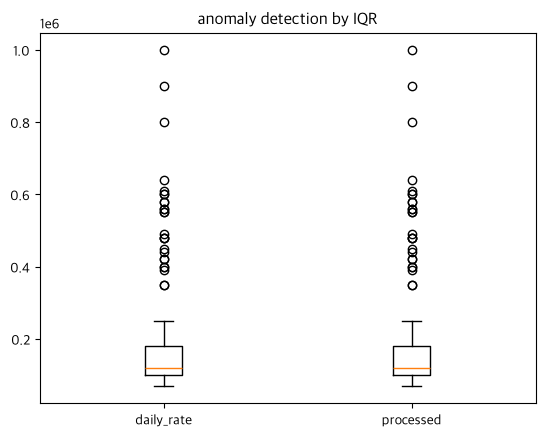

In [86]:
plt.boxplot(booking_clean[['daily_rate', 'daily_rate_processed']],\
           tick_labels=['daily_rate', 'processed'])
plt.title('anomaly detection by IQR')
plt.show()

## 문제 4. 업무에 필요한 파생변수 생성

In [91]:
# 파생변수 정의
booking_clean['total_nights'] = booking_clean['weekend_nights'] + \
                                booking_clean['weekday_nights']
booking_clean['total_guests'] = booking_clean['adults'] +\
                                booking_clean['children']

booking_clean['estimated_room_amount'] = \
        booking_clean['daily_rate'] * booking_clean['total_nights']

booking_clean['lead_time_group'] = \
        booking_clean['lead_time'].apply(lambda lt:\
                'Within7Days' if 0 <= lt <= 7 else \
                '8to30Days' if 7 < lt <= 30 else \
                'Over30Days')

In [94]:
# total 집계
abnormal_total = (booking_clean['total_nights'] == 0) | (booking_clean['total_guests'] == 0)
print('total_night = 0 or total_guests = 0 예약 정보')
print('booking_id:')
print(list(booking_clean.loc[abnormal_total, 'booking_id']))
print(f'number: {abnormal_total.sum()}')


total_night = 0 or total_guests = 0 예약 정보
booking_id:
['HB0052', 'HB0054', 'HB0053', 'HB0051']
number: 4


In [97]:
# 제외
booking_clean = booking_clean.loc[~abnormal_total]

print(f'최종 행 수: {len(booking_clean)}')

# 주요 열 처음 10개 행
booking_clean[['total_nights', 'total_guests', 'estimated_room_amount', 'lead_time_group']].head(10)

최종 행 수: 281


,total_nights,total_guests,estimated_room_amount,lead_time_group
0,7.0,3.0,1260000.0,8to30Days
1,4.0,2.0,520000.0,Within7Days
2,6.0,1.0,420000.0,8to30Days
3,5.0,4.0,650000.0,8to30Days
4,4.0,3.0,480000.0,Over30Days
5,5.0,4.0,500000.0,Over30Days
6,3.0,2.0,480000.0,Over30Days
7,3.0,1.0,1650000.0,8to30Days
8,4.0,2.0,1800000.0,Within7Days
9,2.0,3.0,160000.0,Over30Days


In [98]:
# lead_time이 7일일때와 30일일 때 각각 올바른 구간에 포함되는지 확인
lead_time_7 = booking_clean['lead_time'] == 7
lead_time_7 = set(lead_time_7.index[lead_time_7])
lead_time_30 = booking_clean['lead_time'] == 30
lead_time_30 = set(lead_time_30.index[lead_time_30])
lead_time_7_cls = booking_clean['lead_time_group'] == 'Within7Days'
lead_time_7_cls = set(lead_time_7_cls.index[lead_time_7_cls])
lead_time_30_cls = booking_clean['lead_time_group'] == '8to30Days'
lead_time_30_cls = set(lead_time_30_cls.index[lead_time_30_cls])

print(f'lead_time = 7이 Within7Days에 포함?: {lead_time_7<=lead_time_7_cls}')
print(f'lead_time = 30이 8to30Days에 포함?: {lead_time_30<=lead_time_30_cls}')

lead_time = 7이 Within7Days에 포함?: True
lead_time = 30이 8to30Days에 포함?: True


### 설명
* 파생변수의 사용: total_nights는 예약 당 전체 숙박일을 알려줌. total_guests는 예약 당 몇명이 투숙하는 지 알려줌. estimated_room_amount는 해당 예약에서 발생한 매출을 알 수 있음. lead_time_group은 이용객이 올 때 까지의 시간에 따라 방을 어떻게 준비할 수 있을지, 몇일 후 예상 현금 흐름 계산, 기간에 따른 예약 취소 가능성 고려에 사용 가능.
* estimated_room_amount는 아직 예약된 금액이지 실제로 들어온 현금이 아니다. lead_time=0이 되고 실제로 현금이 들어오기 전까지는 예상일 뿐이다. 그리고 예약이 변경되어 숙박일 수가 달라질 가능성도 있다.

## 문제 5. 사전 확인 대상 예약 추출

In [112]:
# 4조건 사전 확인 대상 예약
selected = booking_clean[\
            (booking_clean['is_canceled'] == 0) & \
            (booking_clean['lead_time'] >= 60) & \
            (booking_clean['total_nights'] >= 3) & \
            (booking_clean['booking_channel'].isin(['Online', 'Agency']))\
        ]


In [113]:
printing_cols = ['booking_id', 'booking_channel', 'lead_time', 'total_nights', 'total_guests', 'estimated_room_amount']
selected[printing_cols]

,booking_id,booking_channel,lead_time,total_nights,total_guests,estimated_room_amount
4,HB0234,Agency,171.0,4.0,3.0,480000.0
13,HB0046,Online,137.0,5.0,1.0,600000.0
20,HB0079,Agency,100.0,3.0,1.0,210000.0
24,HB0105,Online,78.0,4.0,1.0,440000.0
26,HB0282,Online,76.0,5.0,2.0,400000.0
39,HB0074,Online,75.0,3.0,2.0,240000.0
41,HB0077,Agency,150.0,3.0,2.0,750000.0
44,HB0078,Online,80.0,3.0,4.0,420000.0
46,HB0235,Agency,164.0,5.0,1.0,550000.0
50,HB0181,Agency,79.0,7.0,2.0,1260000.0


In [114]:
selected[printing_cols].sort_values('estimated_room_amount', ascending=False).head(10)

,booking_id,booking_channel,lead_time,total_nights,total_guests,estimated_room_amount
198,HB0028,Online,154.0,4.0,2.0,1920000.0
149,HB0084,Online,157.0,6.0,3.0,1440000.0
50,HB0181,Agency,79.0,7.0,2.0,1260000.0
292,HB0122,Online,133.0,4.0,2.0,1000000.0
52,HB0240,Online,115.0,7.0,1.0,910000.0
78,HB0067,Online,60.0,5.0,2.0,900000.0
232,HB0292,Online,154.0,5.0,4.0,900000.0
93,HB0225,Agency,84.0,7.0,2.0,840000.0
41,HB0077,Agency,150.0,3.0,2.0,750000.0
140,HB0116,Online,92.0,4.0,2.0,720000.0


In [115]:
print(f'사전 확인 대상 예약 전체 건수: {len(selected)}')
print(f'사전 확인 대상 예상 요금 합계: {int(selected["estimated_room_amount"].sum())}')

사전 확인 대상 예약 전체 건수: 35
사전 확인 대상 예상 요금 합계: 21510000


In [117]:
# 사전 확인 대상 조건 손 검증

violated = []
for idx, row in selected.iterrows():
    violation = {
        'booking_id': row['booking_id'],
        'canceled': not(row['is_canceled'] == 0),
        'short_lead_time': not(row['lead_time'] >= 60),
        'short_nights': not(row['total_nights'] >= 3),
        'normal_channel': not(row['booking_channel'] in ['Online', 'Agency'])
    }
    flag = 0
    for n in violation:
        if n == 'booking_id':
            continue

        if violation[n]:
            flag = 1
            break
    if flag == 1:
        violated.append(violation)

print(f'사전 확인 대상 조건 손 검증 위반 수: {len(violated)}')
print('위반 정보')
violated = pd.DataFrame(violated)
violated

사전 확인 대상 조건 손 검증 위반 수: 0
위반 정보


""


## 문제 6. 예약 현황과 취소 비율 시각화

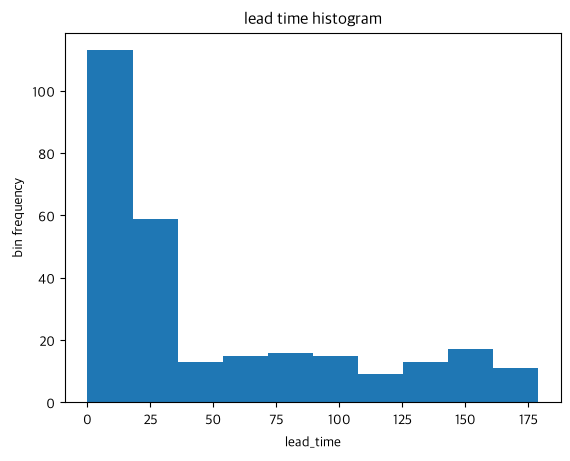

In [140]:
# 입실 예약이 몇일 전?
plt.hist(booking_clean['lead_time'])
plt.title('lead time histogram')
plt.xlabel('lead_time')
plt.ylabel('bin frequency')
plt.show()

### 설명
입실 30일전, 한달 정도 되는 구간에 예약이 몰려있다.

예약 경로별 정보:
                 booking_id  is_canceled  cancel_rate
booking_channel                                      
Agency                   53            9    16.981132
Direct                   83           13    15.662651
Online                  141           42    29.787234
Unknown                   4            1    25.000000


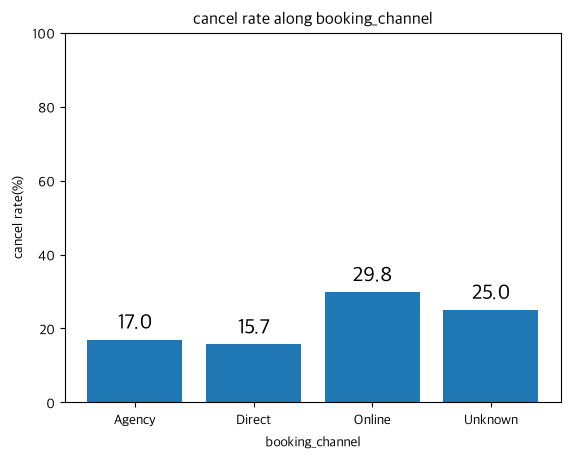

In [164]:
# 예약 경로별 취소 현황
channel_info = \
booking_clean.groupby('booking_channel').aggregate(\
    {
        'booking_id': 'count',
        'is_canceled': 'sum'
    })
channel_info['cancel_rate'] = \
    channel_info['is_canceled'] / channel_info['booking_id'] * 100

print('예약 경로별 정보:')
print(channel_info)

cib = plt.bar(channel_info.index, channel_info['cancel_rate'])
plt.bar_label(cib, fmt='%.1f', padding=3, fontsize=15)
plt.title('cancel rate along booking_channel')
plt.xlabel('booking_channel')
plt.ylabel('cancel rate(%)')
plt.ylim([0, 100])
plt.show()

### 설명
온라인이나 알 수 없는 예약 채널을 이용한 경우 취소율이 두드러진다. Unknown은 데이터 수가 4개 밖에 없으므로 통계적 유의성은 없다.

lead time group에 따른 취소율 정보
                 booking_id  is_canceled  cancel_rate
lead_time_group                                      
Within7Days              69           12    17.391304
8to30Days               100           13    13.000000
Over30Days              112           40    35.714286


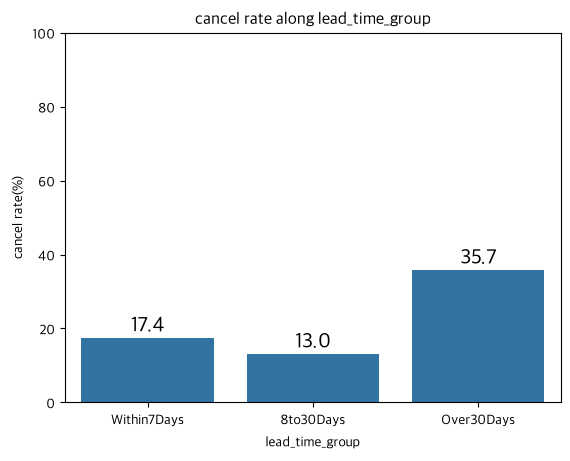

In [171]:
# 예약 선행일 수 구간 별 취소 현황 비교
import seaborn as sb

channel_info = \
booking_clean.groupby('lead_time_group').aggregate(\
    {
        'booking_id': 'count',
        'is_canceled': 'sum'
    })
channel_info['cancel_rate'] = \
    channel_info['is_canceled'] / channel_info['booking_id'] * 100

channel_info = channel_info.iloc[[2,0,1]]

print('lead time group에 따른 취소율 정보')
print(channel_info)

ax = sb.barplot(data = channel_info, x='lead_time_group', y='cancel_rate')
ax.bar_label(ax.containers[0], fmt='%.1f', fontsize=15)
plt.title('cancel rate along lead_time_group')
plt.ylabel('cancel rate(%)')
plt.ylim([0, 100])
plt.show()

### 설명
30일 넘게 남은 경우에 예약을 취소하는 비율이 높다.

## 문제 7. 예약 운영팀에 분석 결과 전달

### 주요 데이터 품질 문제와 처리 방법
* weekend_nights, weekday_nights, lead_time, adults, children이 음수일 수 없음에도 음수인 경우가 있었음. -> na로 처리 후 이 필드 중 하나라도 na면 제거.
* daily_rate도 항상 양수여야 하는데 음수가 있었음. -> na로 처리 후 중앙값으로 대체.
* booking_channel, room_type 결측이 있었음. -> Unknown으로 대체

### 차트에서 확인한 예약/취소 특성
* 숙박일까지 시간이 많이 남았으면 많이 취소하는 경향이 뚜렷하다.
* 온라인 신청한 경우 취소하는 경향이 더 있으며 어떤 채널로 예약했는지 모르는 경우 취소율이 높으나 4건밖에 없었으므로 단정하기 어렵다.
* 숙박일까지 30일 남은 경우가 가장 많으며 이 경우는 취소율이 상대적으로 낮다.

### 사전 확인 대상 예약의 건수와 특징
* 사전 확인 대상은 여유 있게 숙박일 60일 전에 3일 이상 오래 투숙하는 경우, 온라인과 대행사를 통해서 예약했으며 아직 취소하지 않은 그룹이다.
* 총 35건이 사전 확인 대상이 되었으며 예상 수입은 2200만원 규모다.

### 운영팀이 추가로 검토하면 좋을 사항 한 가지
* Suite 방 타입의 숙박 가격이 천차만별인데 Suite 안에서도 세부 클래스가 있는지 점검 필요. 가격이 높기 때문에 충분히 여유 있는 사람이 신중하게 선택했을 가능성이 있고 취소율이 낮을 수도 있다.


### 분석의 한계 또는 추가로 필요한 데이터 한 가지
* 전체 시간 프레임에서 통계가 유지되리라는 보장이 없음.(현실의 사회적 데이터는 IID 가정 쉽게 위반)
* 따라서 예약을 언제 했는지 시간 정보와 외부 이벤트가 취소율 분석에 결합되면 좋다.